# Assignment 3 - Data Analysis

## Data set Introduction - Persons living in acceptable housing

I found this data set via Statistics Canada from the period 2020-2021.

The reason I chose this is to get a deeper understanding on people living in acceptable housing versus not living in acceptable housing, based on factors such as location, housing tenure, and year. The dataset is mostly metadata and government referencing, but with the columns left over after dropping unimportant columns we can still uncover patterns with the deciding columns. 

This dataset comes from the Canadian Housing Survey, which collects information from households and produces summarized statistics. The values in the dataset are already aggregated percentages rather than raw individual-level data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import your helper module
import sys
sys.path.insert(0, '..')
from src.helpers import *

In [2]:
import pandas as pd
df = pd.read_csv('../data/housing2022.csv')

# What is acceptable housing?

The definition of acceptable housing is based on Statistics Canada's criteria, which include affordability, adequacy, and suitability.

**Affordability** refers to whether housing costs are reasonable relative to a household’s income. \
**Adequacy** refers to the physical condition of the home, such as whether it requires major repairs. \
**Suitability** refers to whether the housing has enough space for the people living in it.

For housing to be considered acceptable, it must meet all three of these conditions. If a household fails to meet even one of them, it is classified as living in unacceptable housing.

# Initial Exploration 

In [3]:
df.shape

(364, 17)

### `df.shape` 

Using `df.shape`, I can see that the dataset has 364 rows and 17 columns.

At first, 364 rows seems small for data that represents all of Canada, but this makes sense after considering that the dataset is aggregated. Each row represents a combination of factors like region, tenure, housing status, and year, rather than individual people.

Because of this, the dataset is smaller but still useful. Instead of analyzing individuals, the focus will be on comparing patterns between groups.

In [4]:
df.head()

,REF_DATE,GEO,DGUID,Tenure including first-time homebuyer and social and affordable housing status,Acceptable housing,Statistics,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,2021,Canada (excluding territories),2021A000011124,"Total, by tenure",Does not live in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264166,1.1.1.1,29.0,NaN,NaN,NaN,1
1,2022,Canada (excluding territories),2021A000011124,"Total, by tenure",Does not live in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264166,1.1.1.1,31.0,NaN,NaN,NaN,1
2,2021,Canada (excluding territories),2021A000011124,"Total, by tenure",Lives in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264172,1.1.11.1,71.0,NaN,NaN,NaN,1
3,2022,Canada (excluding territories),2021A000011124,"Total, by tenure",Lives in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264172,1.1.11.1,69.0,NaN,NaN,NaN,1
4,2021,Canada (excluding territories),2021A000011124,Owner household,Does not live in acceptable housing,Percentage of persons,Percent,239,units,0,v1544264232,1.2.1.1,22.0,NaN,NaN,NaN,1


In [5]:
df['UOM'].unique()

array(['Percent'], dtype=object)

In [6]:
df['SCALAR_FACTOR'].unique()

array(['units'], dtype=object)

In [7]:
df['SCALAR_ID'].unique()

array([0])

**`df['UOM'].unique()`** confirms that `UOM` column only contains the value "Percent". Since this value doesn't change, it is not necessary to keep for analysis. I also checked `SCALAR_FACTOR`, `SCALAR_ID`, `UOM_ID`, `STATISTICS`, and `DECIMAL`, the result was the same. The value was the same throughtout the dataset, so no need to keep the columns for further analysis.  

In [8]:
df['STATUS'].isna().sum()

np.int64(364)

**df['STATUS'].isna().sum()** produces the result that every row for `STATUS` is NaN, so this confirms it is not suitable to keep for analysis as it has no significance because it is the same through out. This is also the case for `SYMBOL` and `TERMINATED`

In [9]:
df['DGUID'].nunique()

13

In [10]:
df['COORDINATE'].nunique()

182

To check if columns like `DGUID` were useful, I ran **`df['DGUID'].nunique()`** to see how many unique values it contains. The result was **13**, which matches the number of regions in the dataset.

This suggests that `DGUID` acts as an identifier for each region rather than providing new analytical information. Since it does not add meaningful insight beyond labeling regions, it was removed during the cleaning process.

I also used this method to check `VECTOR` and `COORDINATE` and the results were the **182 unique values** which is half of **364** (rows in dataset), so this suggests that these columns are for each year and are also used for reference only and provide no insight for analysis.

## `df.head()`
---

I used `df.head()` to view the first few rows of the dataset and understand its structure.

From this preview and the above further analysis, I concluded that the dataset contains both useful variables and metadata. Columns such as `Statistics`, `UOM`, `DGUID`, `VECTOR`, `COORDINATE`, `STATUS`, and `SYMBOL` are metadata used by Statistics Canada for organization and reference, rather than analysis.


Based on the dataset documentation:
- **DGUID**: geographic identifier  
- **VECTOR**: internal table reference code  
- **COORDINATE**: position in the data table  
- **UOM / SCALAR**: units and scaling of values  
- **STATUS / SYMBOL**: data quality indicators  

Since these columns do not contribute meaningful analytical information, they were removed to simplify the dataset.

The key variables used for analysis are:
- `REF_DATE`: year of data collection  
- `GEO`: region  
- `Tenure`: type of housing (owner or renter)  
- `Acceptable Housing`: whether housing is acceptable  
- `VALUE`: percentage of people in each group  

These variables allow for comparison of housing conditions across regions, tenure types, and time.


In [11]:
df.value_counts('GEO')

GEO
Alberta                           28
Atlantic Region                   28
British Columbia                  28
Canada (excluding territories)    28
Manitoba                          28
New Brunswick                     28
Newfoundland and Labrador         28
Nova Scotia                       28
Ontario                           28
Prairies Region                   28
Prince Edward Island              28
Quebec                            28
Saskatchewan                      28
Name: count, dtype: int64

## Looking Deeper into Regions

To better understand how the dataset is structured, I examined the number of rows for each region using `df.value_counts('GEO')` and by filtering to only look at "Manitoba"(code below).

From this, I noticed that every region consistently contains 28 rows. This pattern suggested that the data is not random, but organized into specific combinations.

Looking more closely, I found that each region includes:
- 7 tenure categories  
- 2 housing statuses (Acceptable and Not Acceptable)  
- 2 years  

When these are combined (7 × 2 × 2), they result in 28 unique combinations per region. This shows that each row represents a specific grouping of year, tenure, and housing status, rather than individual observations.

In [12]:
df[df["GEO"] == "Manitoba"][[
    "REF_DATE",
    "GEO",
    "Tenure including first-time homebuyer and social and affordable housing status",
    "Acceptable housing",
    "VALUE"
]]

,REF_DATE,GEO,Tenure including first-time homebuyer and social and affordable housing status,Acceptable housing,VALUE
252,2021,Manitoba,"Total, by tenure",Does not live in acceptable housing,29.0
253,2022,Manitoba,"Total, by tenure",Does not live in acceptable housing,28.0
254,2021,Manitoba,"Total, by tenure",Lives in acceptable housing,71.0
255,2022,Manitoba,"Total, by tenure",Lives in acceptable housing,72.0
256,2021,Manitoba,Owner household,Does not live in acceptable housing,23.0
257,2022,Manitoba,Owner household,Does not live in acceptable housing,21.0
258,2021,Manitoba,Owner household,Lives in acceptable housing,77.0
259,2022,Manitoba,Owner household,Lives in acceptable housing,79.0
260,2021,Manitoba,"Owner household, first-time homebuyer",Does not live in acceptable housing,18.2
261,2022,Manitoba,"Owner household, first-time homebuyer",Does not live in acceptable housing,24.0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364 entries, 0 to 363
Data columns (total 17 columns):
 #   Column                                                                          Non-Null Count  Dtype  
---  ------                                                                          --------------  -----  
 0   REF_DATE                                                                        364 non-null    int64  
 1   GEO                                                                             364 non-null    object 
 2   DGUID                                                                           364 non-null    object 
 3   Tenure including first-time homebuyer and social and affordable housing status  364 non-null    object 
 4   Acceptable housing                                                              364 non-null    object 
 5   Statistics                                                                      364 non-null    object 
 6   UOM               

### `df.info()` 

Running `df.info()` gave a clearer picture of the dataset’s overall structure. It shows that the dataset contains 17 columns and 364 rows, along with the data types for each column.

From this output, I observed three main data types: `float64` (decimal values), `int64` (integers), and `object` (text-based data). This helps confirm what kind of information each column holds.

A key observation was that the `STATUS`, `SYMBOL`, and `TERMINATED` columns all contain 0 non-null values. This means they do not hold any usable data in this dataset, which further supports the decision to remove them during the cleaning process.

This step helped confirm both the structure of the dataset and which columns were unnecessary for analysis.


In [14]:
df.describe()

,REF_DATE,UOM_ID,SCALAR_ID,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
count,364.000000,364.0,364.0,364.000000,0.0,0.0,0.0,364.0
mean,2021.500000,239.0,0.0,50.000000,NaN,NaN,NaN,1.0
std,0.500688,0.0,0.0,22.118484,NaN,NaN,NaN,0.0
min,2021.000000,239.0,0.0,10.900000,NaN,NaN,NaN,1.0
25%,2021.000000,239.0,0.0,30.000000,NaN,NaN,NaN,1.0
50%,2021.500000,239.0,0.0,50.000000,NaN,NaN,NaN,1.0
75%,2022.000000,239.0,0.0,70.000000,NaN,NaN,NaN,1.0
max,2022.000000,239.0,0.0,89.100000,NaN,NaN,NaN,1.0


### `df.describe()`
When we run `df.describe()` we are only running the intergers and float data types, and honestly the only one worth looking at is `VALUE` as this number represents our predicting column. All other columns are ones I plan to drop, besides the `REF_DATE` but running `describe()` on a date has no significance, other than our dataset spans from 2021-2022.

`VALUE` percentage of people in acceptable or unacceptable housing 

- min of 10.9 %
- max of 89.1%
- avg of 50%
- The wide range in values suggests that housing conditions vary significantly depending on location and tenure.
- The standard deviation (22.1) indicates a relatively high level of variability in housing conditions across the dataset.
- Columns such as `UOM_ID`, `SCALAR_ID`, and `DECIMALS` have constant values, further evidence to drop the columns later.


# Analytical Questions

1. Do renters experience a higher percentage of unacceptable housing compared to homeowners?

2. Which provinces have the highest and lowest percentages of people living in unacceptable housing?

3. How do housing conditions differ between first-time homebuyers and non-first-time homeowners?

4. How have housing conditions changed between 2021 and 2022 across different regions?

### Observations

1. The dataset contains 364 rows and 17 columns, indicating a moderately sized dataset suitable for analysis.

2. The data includes information for two years, 2021 and 2022, which allows for basic comparison over time.

3. The dataset includes multiple categories of housing tenure, such as owners, renters, and first-time homebuyers.

4. The dataset will be reduced in columns, but there is many comparisons to make from how much information is in each column.

5. The values are represented as percentages, making it easier to compare housing conditions across different groups.

6. Several columns (such as DGUID, VECTOR, and COORDINATE) appear to be metadata and do not contribute meaningful information for analysis.

# Cleaning the Dataset

### Clean column names
I standarized column names to ensure consistency and make them easier to read and work with during analysis. 

### Drop unnecessary columns
When I looked over the dataset for the first time, I right away noticed that most of the columns were not needed, as they were for government reference and metadata that will not add anything to the analysis. So we drop them from our cleaned dataset. This will get rid of anything we don't need to see.

### Rename columns
Now for the next cleaning step, I want to rename the remaining column names into more user friendly names by creating a dictionary in the `helpers.py` folder. For example, "Ref Date" to "Year" is easier to understand.

### Simplify Tenure category values
I am going to simplify the names in the Tenure column, as the original titles are too long and having them shorter will be best for later visualization.


### Make Tenure Group
I am going to make another group for Tenure to keep valuable information such as if they are first time buyer or on social assistance, because I think this could be interesting to compare with each other. \
I will simplify the groups so we can do analysis on three simple groups as well as the more detailed Tenure.

### Simplify Housing status values
I simplified the housing status labels by shortening the long descriptions to easier shorter names. "Does not live in acceptable housing" now simply becomes "Not Acceptable". This will improve readability for our future analysis.

In [15]:
df_cleaned = clean_column_names(df)
df_cleaned = drop_metadata_columns(df_cleaned)
df_cleaned = rename_columns(df_cleaned)
df_cleaned = add_tenure_group(df_cleaned)
df_cleaned = simplify_tenure(df_cleaned)
df_cleaned = simplify_housing_status(df_cleaned)
df_cleaned.columns

Index(['Year', 'Region', 'Tenure', 'Housing Status', 'Percentage',
       'Tenure Group'],
      dtype='object')

In [16]:
df_cleaned

,Year,Region,Tenure,Housing Status,Percentage,Tenure Group
0,2021,Canada (excluding territories),Total,Not Acceptable,29.0,Total
1,2022,Canada (excluding territories),Total,Not Acceptable,31.0,Total
2,2021,Canada (excluding territories),Total,Acceptable,71.0,Total
3,2022,Canada (excluding territories),Total,Acceptable,69.0,Total
4,2021,Canada (excluding territories),Owner,Not Acceptable,22.0,Owner
...,...,...,...,...,...,...
359,2022,British Columbia,Renter (Non-social),Acceptable,49.0,Renter
360,2021,British Columbia,Renter (Social),Not Acceptable,41.0,Renter
361,2022,British Columbia,Renter (Social),Not Acceptable,48.0,Renter
362,2021,British Columbia,Renter (Social),Acceptable,59.0,Renter


### Cleaning Complete

After working through the cleaning steps, the dataset became much simpler and easier to understand. Removing the unnecessary metadata columns helped reduce clutter and made it clearer which variables are actually useful for analysis.

I also standardized the column names to keep everything consistent, and simplified some of the category values so they are easier to read and compare. In addition, I created a new column to group tenure values, which will help when comparing broader patterns.

With these changes, the dataset is now more organized and ready to be used for further analysis.

---

# Visualizations to answer Analytical Questions

### Question 1: Do renters experience a higher percentage of unacceptable housing compared to homeowners?

Let's begin with the first question, I want to compare housing conditions between renters and homeowners. Since these groups represent different housing situations, this comparison will allow us to visualize if one group is more likely to have acceptable housing or not.


<function matplotlib.pyplot.show(close=None, block=None)>

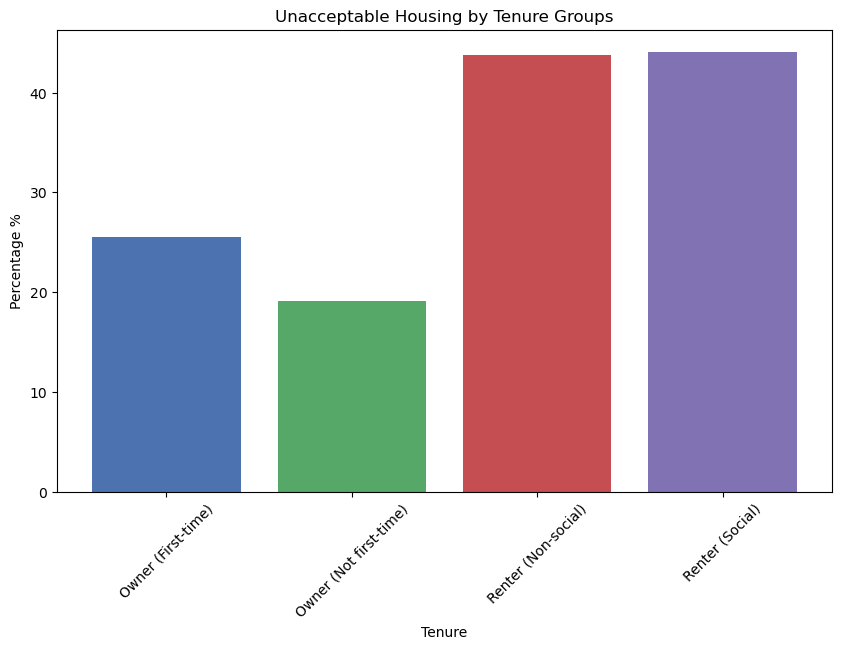

In [19]:
# we only want one group so we filter to "not acceptable"
unacceptable = df_cleaned[df_cleaned["Housing Status"] == "Not Acceptable"]

unacceptable = unacceptable[
    unacceptable["Tenure"].isin([
        "Owner (First-time)",
        "Owner (Not first-time)",
        "Renter (Social)",
        "Renter (Non-social)"
    ])
]

# remove total
tenure_unacceptable = unacceptable.groupby("Tenure")["Percentage"].mean()

# create plot
fig, ax = plt.subplots(figsize=(10, 6))

# nice different colours
colours = ["#4c72b0", "#55a868", "#c44e52", "#8172b3"]
ax.bar(tenure_unacceptable.index, tenure_unacceptable.values, color = colours)

# labels
ax.set_title("Unacceptable Housing by Tenure Groups")
ax.set_xlabel("Tenure")
ax.set_ylabel("Percentage %")
ax.tick_params(axis = 'x', rotation = 45)

plt.show

# Bar plot - Unacceptable housing percentages

When we look at this chart, the difference in Renter vs. Homeowner stands out. Renters are more likely to live in unacceptable housing. 

Homeowners have lower percentages of unacceptable housing, the average is around 20-25% range. On the other hand, all renter categories are much higher, sitting above the 40% range. The gap is consistent, even when renters are broken down further into social and non-social housing. 

The interesting thing about this chart, is that no renter group falls close to the homeowner range, which shows a consistent pattern across all renter types.

From this observation, we can see that renters are more likely to experience unacceptable housing conditions compared to homeowners. So, Tenure plays a significant role in housing quality.

### Question 2: Which provinces have the highest and lowest percentages of people living in acceptable housing?

To answer this question, I want to compare percentages of people living in unacceptable housing across different regions. This helps identify which provinces experience the highest and lowest housing challenges.

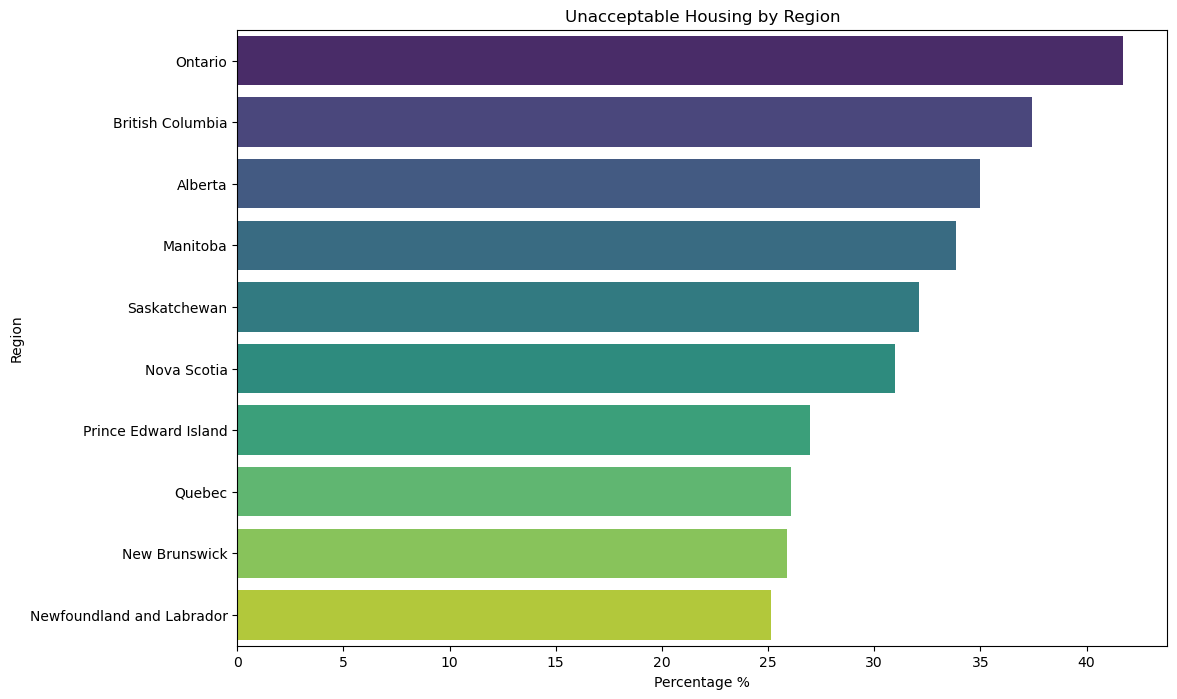

In [23]:
# filter to only unacceptable housing

unacceptable = df_cleaned[df_cleaned["Housing Status"] == "Not Acceptable"]

# remove Canada (not a province)
unacceptable = unacceptable[unacceptable["Region"].isin([
        "Newfoundland and Labrador",
        "Prince Edward Island",
        "Nova Scotia",
        "New Brunswick",
        "Quebec",
        "Ontario",
        "Manitoba",
        "Saskatchewan",
        "Alberta",
        "British Columbia"])
]

# Group by region and calculate average
region_unacceptable = unacceptable.groupby("Region")["Percentage"].mean()

# sort values 
region_unacceptable = region_unacceptable.sort_values(ascending = False)

# convert to Dataframe using Seaborn
region_unacceptable = region_unacceptable.reset_index()

# create plot

fig, ax = plt.subplots(figsize = (12, 8))

sns.barplot(
    data = region_unacceptable,
    x = "Percentage",
    y = "Region",
    hue = "Region",
    ax = ax,
    palette = "viridis",
    legend = False
)

# labels
ax.set_title("Unacceptable Housing by Region")
ax.set_xlabel("Percentage %")
ax.set_ylabel("Region")

plt.show()



# Horizontal Bar Chart - Unacceptable housing across Canada

Looking at this chart, there is a clear difference in the percentage of people living in unacceptable housing across regions.

Ontario stands out as having the highest percentage, while Newfoundland and Labrador has the lowest. Other provinces fall in between, with western provinces such as British Columbia and Alberta also showing relatively higher percentages compared to others.

This variation suggests that housing conditions are not evenly distributed across Canada, and that location plays an important role in the likelihood of experiencing unacceptable housing.

One factor that could be considered is population size, as larger provinces may have more people overall. However, since the data is represented as percentages, the results are already adjusted for population size. This means the differences shown reflect proportions rather than total counts.

Overall, the chart highlights regional disparities in housing conditions and shows that some provinces experience greater housing challenges than others.